# Module 6 — Random Walks, Markov Chains and the Poisson Process

**Probability Simulation Laboratory** · Module 6 of 8

## Learning objectives
1. define a stochastic process $\{X_t\}$ as an indexed family of random variables, and distinguish discrete from continuous time and state;
2. derive and verify the mean, variance and distribution of a simple random walk;
3. use the **martingale** idea to solve the gambler's-ruin problem, and check the answers against the *fundamental matrix* of an absorbing Markov chain;
4. compute and simulate the **stationary distribution** of a finite Markov chain, its convergence, and the mean return time $1/\pi_i$;
5. simulate a **Poisson process** and verify that counts are Poisson and inter-arrival times exponential.

## Research objective
Understand how random processes evolve over time and investigate their mathematical properties.

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "06_stochastic_processes" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import stochastic as sp        # 06_stochastic_processes/src/stochastic.py

## 1. Mathematical background

**Stochastic process.** A family $\{X_t:t\in T\}$ of random variables on a common probability space. $T$ is the *index set* (time): $\{0,1,2,\dots\}$ (discrete time) or $[0,\infty)$ (continuous time). The *state space* is the set of values of $X_t$. A *sample path* is the function $t\mapsto X_t(\omega)$ for fixed $\omega$.

**Simple random walk.** $S_0=0$, $S_n=\sum_{i=1}^nX_i$, $X_i$ i.i.d. with $P(X_i=+1)=p$, $P(X_i=-1)=q=1-p$.
* $\mathbb ES_n=n(p-q)$; $\operatorname{Var}S_n=4npq$. For the *symmetric* walk $\mathbb ES_n=0$, $\operatorname{Var}S_n=n$, so typical displacement $\sim\sqrt n$.
* $S_n=2K-n$ with $K\sim\text{Binomial}(n,p)$ (the number of up-steps): the exact law is binomial, and $S_n$ has the parity of $n$.
* *Martingale property* (symmetric case): $\mathbb E[S_{n+1}\mid S_0,\dots,S_n]=S_n$; also $S_n^2-n$ is a martingale. A martingale is a "fair game": expected future value equals current value.
* **2D walk** on $\mathbb Z^2$: each step is E/W/N/S with probability $\tfrac14$; $\mathbb E|S_n|^2=n$ (the squared distance is a sum of $n$ unit increments plus uncorrelated cross terms).

**Gambler's ruin.** A gambler with fortune $i\in\{0,\dots,N\}$ wins each round with probability $p$ (+1) and loses with probability $q$ (−1); play stops at $0$ or $N$.
*Fair case ($p=\tfrac12$).* $S_n$ is a martingale and the stopping time $T$ (time to hit $\{0,N\}$) is bounded in expectation, so by optional stopping $i=\mathbb E[S_T]=N\cdot P_i(\text{hit }N)$, giving
$$P_i(\text{ruin avoided: hit }N)=\frac iN,\qquad \mathbb E_i[T]=i(N-i)\quad(\text{from the martingale }S_n^2-n).$$
*Biased case.* With $r=q/p\neq1$: $P_i(\text{hit }N)=\dfrac{1-r^i}{1-r^N}$, $\ \mathbb E_i[T]=\dfrac{i}{q-p}-\dfrac N{q-p}\cdot\dfrac{1-r^i}{1-r^N}$.
Even a slightly unfavourable game ($p<\tfrac12$) makes ruin very likely when $N$ is large.

**Markov chain.** A process $X_0,X_1,\dots$ on a finite state space $\{1,\dots,k\}$ with the Markov property $P(X_{n+1}=j\mid X_n=i,X_{n-1},\dots)=P_{ij}$. The matrix $P=(P_{ij})$ is *stochastic* (rows sum to 1). The $n$-step transition matrix is $P^n$, and if $\mu_0$ is the initial distribution (row vector) then $\mu_n=\mu_0P^n$.
**Stationary distribution.** $\pi$ with $\pi P=\pi$, $\sum\pi_i=1$. If the chain is *irreducible* and *aperiodic* then $\pi$ is unique, $\mu_n\to\pi$ for every start, the long-run fraction of time in state $i$ is $\pi_i$ (ergodic theorem), and the **mean return time** to $i$ is $1/\pi_i$ (Kac).
The speed of convergence is governed by the second-largest eigenvalue modulus $|\lambda_2|$: $\|\mu_n-\pi\|_{TV}=O(|\lambda_2|^n)$.
**Absorbing chains.** If the transient-to-transient block is $Q$ and transient-to-absorbing block $R$, then $F=(I-Q)^{-1}$ (the *fundamental matrix*) gives expected visits; $F\mathbf 1$ the expected steps to absorption and $FR$ the absorption probabilities.

**Poisson process.** A counting process $N(t)$ with $N(0)=0$, independent increments, and $N(t)-N(s)\sim\text{Poisson}(\lambda(t-s))$. Equivalent construction: inter-arrival times are i.i.d. Exponential($\lambda$), and arrival times are cumulative sums. Consequences: $\mathbb EN(t)=\operatorname{Var}N(t)=\lambda t$; given $N(t)=m$, the arrival times are distributed as $m$ sorted Uniform$(0,t)$ variables.

## Experiment 6.1

**A. Experiment title.** One-dimensional symmetric random walk: $\mathbb ES_n=0$, $\operatorname{Var}S_n=n$, $S_n=2\,\text{Bin}(n,\tfrac12)-n$, and the martingale property.

**B. Research question.** How does the position of a random walk spread with time, and is its distribution exactly binomial?

**C. Mathematical foundation.**

$S_n=\sum X_i$ with $X_i=\pm1$. $\mathbb ES_n=0$; $\operatorname{Var}S_n=n$ since $\operatorname{Var}X_i=1$ and the steps are independent. $P(S_n=2k-n)=\binom nk2^{-n}$. For large $n$, $S_n/\sqrt n\approx\mathcal N(0,1)$ (CLT, Module 4).
Martingale checks: given $S_n=s$, $\mathbb E[S_{n+1}\mid S_n=s]=s$; and $\mathbb E[S_n^2-n]=0$.

**D. Theoretical prediction.**

Mean $\approx0$ and variance $\approx n$ at every $n$; the empirical pmf of $S_{100}$ matches the binomial pmf on the lattice of even integers; the conditional mean of $S_{101}$ given $S_{100}=s$ equals $s$ for each well-populated $s$.

**E. Experimental design.**

$200{,}000$ paths of length $100$ (and the conditional check using $400{,}000$ paths of length $101$). Plot $40$ sample paths with the $\pm2\sqrt n$ envelope; compare pmf of $S_{100}$ with the exact binomial and normal approximation.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

max |sample mean| over time: 0.0212   (SE of the mean at n=100 is 0.0224)
Var S_n / n at n = 10, 50, 100: [0.9998 0.9936 0.9947]  (theory 1)
total variation distance, empirical vs exact: 0.0039


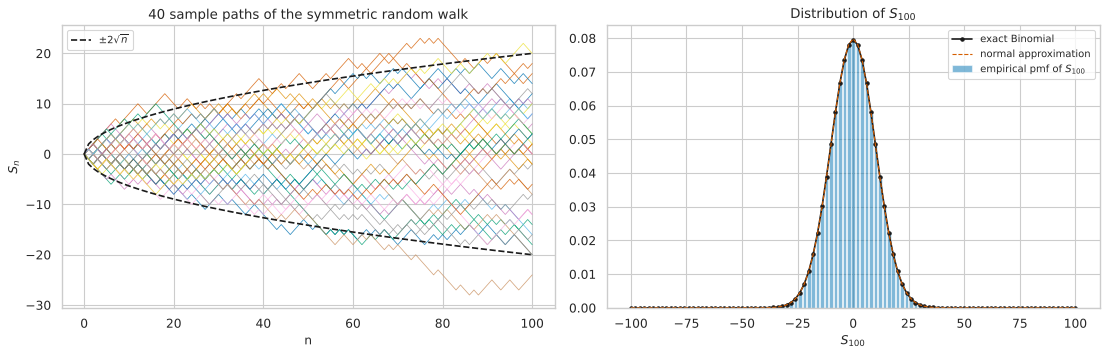

In [3]:
# F. Implementation ------------------------------------------------------------------
# S_n = cumsum of +/-1 steps -> sp.simple_random_walk ;  exact law: S_n = 2K - n, K ~ Binomial(n, 1/2)
rng = make_rng(20261031 + 61)
n_steps, n_paths = 100, 200_000
paths = sp.simple_random_walk(n_steps, n_paths, rng)
steps_axis = np.arange(n_steps + 1)

mean_t = paths.mean(axis=0)
var_t = paths.var(axis=0, ddof=1)
print(f"max |sample mean| over time: {np.abs(mean_t).max():.4f}   (SE of the mean at n=100 is {10 / np.sqrt(n_paths):.4f})")
print(f"Var S_n / n at n = 10, 50, 100: {(var_t[[10, 50, 100]] / np.array([10, 50, 100])).round(4)}  (theory 1)")

# exact binomial pmf for S_100
s_vals = np.arange(-n_steps, n_steps + 1, 2)
exact_pmf = stats.binom.pmf((s_vals + n_steps) // 2, n_steps, 0.5)
emp_pmf = np.array([(paths[:, -1] == s).mean() for s in s_vals])
normal_approx = 2 * stats.norm.pdf(s_vals, scale=np.sqrt(n_steps))        # lattice spacing 2

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for pth in paths[:40]:
    ax[0].plot(steps_axis, pth, lw=0.7, alpha=0.8)
ax[0].plot(steps_axis, 2 * np.sqrt(steps_axis), "k--"); ax[0].plot(steps_axis, -2 * np.sqrt(steps_axis), "k--", label=r"$\pm 2\sqrt{n}$")
ax[0].set(xlabel="n", ylabel="$S_n$", title="40 sample paths of the symmetric random walk"); ax[0].legend()
ax[1].bar(s_vals, emp_pmf, width=1.6, alpha=0.5, label="empirical pmf of $S_{100}$")
ax[1].plot(s_vals, exact_pmf, "k.-", label="exact Binomial")
ax[1].plot(s_vals, normal_approx, "r--", lw=1, label="normal approximation")
ax[1].set(xlabel="$S_{100}$", title="Distribution of $S_{100}$"); ax[1].legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp6_1_random_walk.png")
print(f"total variation distance, empirical vs exact: {0.5 * np.abs(emp_pmf - exact_pmf).sum():.4f}")

In [4]:
# H. Martingale check: E[S_{n+1} | S_n = s] = s -----------------------------------------------------
paths2 = sp.simple_random_walk(101, 400_000, rng)
s100, s101 = paths2[:, 100], paths2[:, 101]
rows = []
for s in [-20, -10, -4, 0, 2, 8, 16]:
    mask = s100 == s
    rows.append(dict(S_100=s, n_paths=int(mask.sum()), mean_of_S_101=s101[mask].mean(), SE=s101[mask].std(ddof=1) / np.sqrt(mask.sum())))
mart = pd.DataFrame(rows).set_index("S_100")
mart["z = (mean - s)/SE"] = (mart.mean_of_S_101 - mart.index) / mart.SE
mart.to_csv(RESULTS / "exp6_1_martingale_check.csv")
display(mart)
print("E[S_n^2 - n] at n = 101:", round(float(np.mean(s101 ** 2) - 101), 3), "+/-", round(float(np.std(s101 ** 2, ddof=1) / np.sqrt(s101.size)), 3))

E[S_n^2 - n] at n = 101: 0.449 +/- 0.226


,n_paths,mean_of_S_101,SE,z = (mean - s)/SE
S_100,,,,
-20,4304,-19.99257,0.01524,0.48773
-10,19240,-10.00312,0.00721,-0.43255
-4,29255,-3.99812,0.00585,0.32156
0,31677,0.00237,0.00562,0.42139
2,31381,2.01099,0.00564,1.94762
8,23368,7.99161,0.00654,-1.28219
16,8983,16.01035,0.01055,0.98123


**H. Theoretical versus empirical comparison.**

The sample mean stays within noise of $0$ and $\operatorname{Var}S_n/n\approx1$ at every time; the empirical pmf of $S_{100}$ follows the exact binomial (total variation distance of order $10^{-3}$, compatible with $200{,}000$ paths) and the normal approximation (which slightly overshoots the peak because of the lattice and the $O(1/n)$ correction). In the conditional table the $z$-scores should be of order 1 (they are not exactly standard normal because of different group sizes), and $\mathbb E[S_n^2-n]$ is within about two standard errors of $0$ (one run; a reminder that $|z|\approx2$ happens about 1 time in 20).

**I. Interpretation.**

Randomness accumulates like $\sqrt n$, not $n$: after $10{,}000$ steps a symmetric walk is typically only about $100$ away from the origin. The martingale property says that *conditioning on the present, the best forecast of the future is the present* — the mathematical formalisation of an efficient market with no drift, and the basis of option-pricing arguments later (Modules 7–8).

**J. Limitations.**

Symmetric $\pm1$ steps on a lattice — real prices have continuous, heavy-tailed increments. Checking a martingale property in simulation only tests *conditional means at the populated states*; rare states have too few paths.

**K. Research conclusion.**

The symmetric walk has mean $0$, variance $n$, binomial law and the martingale property, all confirmed numerically.

**L. Further investigation.**

Estimate the distribution of the *maximum* and the *time of the maximum* of the walk; compare with the arcsine law ($P(\text{last visit to }0\le\alpha n)\to\frac2\pi\arcsin\sqrt\alpha$).

## Experiment 6.2

**A. Experiment title.** Symmetric random walk on $\mathbb Z^2$: $\mathbb E|S_n|^2=n$ and root-mean-square distance $\sqrt n$.

**B. Research question.** How far does a two-dimensional random walker get from the origin?

**C. Mathematical foundation.**

With steps $\xi_i\in\{(\pm1,0),(0,\pm1)\}$ (each with prob. $\tfrac14$): $\mathbb E\xi_i=0$, $\mathbb E|\xi_i|^2=1$ and $\mathbb E[\xi_i\cdot\xi_j]=0$ for $i\ne j$, so $\mathbb E|S_n|^2=n$. Thus RMS distance $=\sqrt n$. Also each coordinate has variance $n/2$.

**D. Theoretical prediction.**

Mean of $|S_n|^2$ equals $n$ at all $n$ (within noise); each coordinate variance $\approx n/2$; the mean *distance* $\mathbb E|S_n|$ is smaller than the RMS distance $\sqrt n$ (by Jensen). For large $n$, $|S_n|^2/n$ is approximately Exponential(mean 1), giving $\mathbb E|S_n|\approx\sqrt{\pi n}/2\approx0.886\sqrt n$.

**E. Experimental design.**

$50{,}000$ walks of $1{,}000$ steps; plot 5 sample paths, and $\mathbb E|S_n|^2$ against $n$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

,mean_sq_distance,theory,var_x,var_y,mean_distance,rms_distance,asymptotic_mean_distance
n,,,,,,,
10,10.03844,10,4.99940,5.03877,2.80942,3.16835,2.80250
100,100.13900,100,49.97279,50.16503,8.86947,10.00695,8.86227
1000,995.58080,1000,495.29196,500.27872,27.95935,31.55283,28.02496


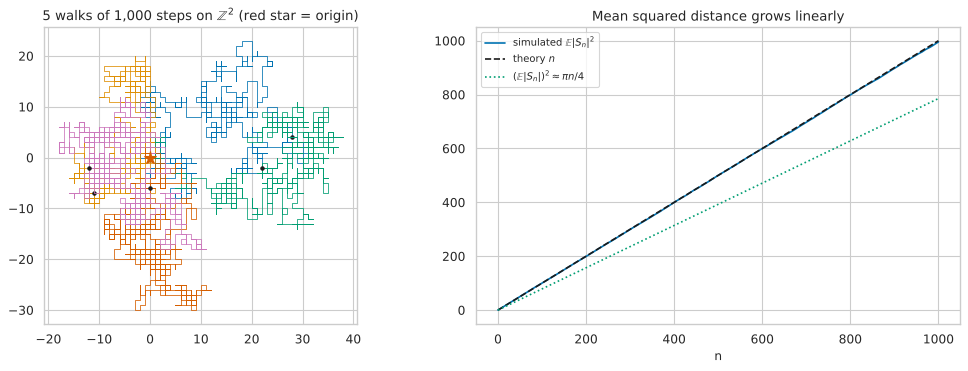

In [5]:
# F/G. Implementation and results ---------------------------------------------------------
rng = make_rng(20261031 + 62)
n_steps, n_paths = 1000, 50_000
x, y = sp.lattice_walk_2d(n_steps, n_paths, rng)
r2 = x.astype(float) ** 2 + y.astype(float) ** 2
t = np.arange(n_steps + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for i in range(5):
    ax[0].plot(x[i], y[i], lw=0.7)
    ax[0].plot(x[i, -1], y[i, -1], "ko", ms=3)
ax[0].plot(0, 0, "r*", ms=12); ax[0].set(aspect="equal", title="5 walks of 1,000 steps on $\\mathbb{Z}^2$ (red star = origin)")
ax[1].plot(t, r2.mean(axis=0), label="simulated $\\mathbb{E}|S_n|^2$"); ax[1].plot(t, t, "k--", label="theory $n$")
ax[1].plot(t, np.pi * t / 4, "g:", label=r"$(\mathbb{E}|S_n|)^2\approx\pi n/4$")
ax[1].set(xlabel="n", title="Mean squared distance grows linearly"); ax[1].legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp6_2_walk2d.png")

rows = []
for n in [10, 100, 1000]:
    rows.append(dict(n=n, mean_sq_distance=r2[:, n].mean(), theory=n, var_x=x[:, n].var(), var_y=y[:, n].var(),
                     mean_distance=np.sqrt(r2[:, n]).mean(), rms_distance=np.sqrt(r2[:, n].mean()), asymptotic_mean_distance=np.sqrt(np.pi * n) / 2))
tab = pd.DataFrame(rows).set_index("n")
tab.to_csv(RESULTS / "exp6_2_walk2d.csv")
display(tab)

**H. Theoretical versus empirical comparison.**

$\mathbb E|S_n|^2$ matches $n$ at every $n$; each coordinate has variance close to $n/2$. The mean distance is below the RMS distance and close to the asymptotic value $\sqrt{\pi n}/2$ (which uses $|S_n|^2/n\approx\text{Exp}(1)$, so $|S_n|/\sqrt n$ is Rayleigh with mean $\sqrt\pi/2$).

**I. Interpretation.**

Diffusive scaling — distance $\propto\sqrt{\text{time}}$ — holds in any dimension and is the discrete shadow of Brownian motion (Module 7). The distinction between $\mathbb E|S_n|$ and $\sqrt{\mathbb E|S_n|^2}$ (Jensen) is a reminder that "typical distance" depends on which average you take.

**J. Limitations.**

Finite $n$ and lattice effects; a lattice walk is not isotropic at small scales.

**K. Research conclusion.**

$\mathbb E|S_n|^2=n$ in two dimensions and $|S_n|\approx\sqrt{\pi n}/2$ on average.

**L. Further investigation.**

Estimate the probability that a 2D walk returns to the origin within $n$ steps for $n=10^2,\dots,10^5$ (recurrence in 2D, only logarithmically slowly) and compare with the 3D walk (transient: return probability $\approx0.34$).

## Experiment 6.3

**A. Experiment title.** Gambler's ruin on $\{0,\dots,20\}$: hitting probabilities $P_i(\text{hit }N)$ and expected duration $\mathbb E_i[T]$ — simulation versus closed form versus the fundamental matrix.

**B. Research question.** How likely is a gambler starting with $i$ units to reach $N$ before ruin, how long does the game last, and what does a small house edge do?

**C. Mathematical foundation.**

Closed forms from the background section. Fair case with $N=20$, $i=10$: $P=\tfrac12$, $\mathbb E[T]=100$. Biased case $p=0.48$ ($r=q/p=13/12$): $P_{10}(\text{hit }20)=\dfrac{1-r^{10}}{1-r^{20}}=\dfrac1{1+r^{10}}\approx0.310$ and $\mathbb E_{10}[T]=\dfrac{10}{0.04}-\dfrac{20}{0.04}\cdot0.310\approx95$. The same numbers must come out of $F=(I-Q)^{-1}$.

**D. Theoretical prediction.**

Fair game from $i=10$: win prob. $0.5$, mean duration $100$. For $p=0.48$: win probability $\approx0.31$ (a $2\%$ per-round edge costs the gambler $19$ percentage points!) and mean duration $\approx95$. Simulation, closed form and matrix computation agree.

**E. Experimental design.**

Simulate $50{,}000$ games from $i=10$ for $p=0.5$ and $p=0.48$; compute closed forms and fundamental-matrix results for *every* starting value $i$ and plot win probability and duration against $i$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

closed forms and fundamental-matrix results agree for every i (assert passed)


p,0.50,0.48
P_win_sim,0.49890,0.31040
wilson_low,0.49452,0.30636
wilson_high,0.50328,0.31447
P_win_closed_form,0.50000,0.30993
P_win_matrix,0.50000,0.30993
E_T_sim,99.89860,94.70556
E_T_SE,0.36514,0.33988
E_T_closed_form,100.00000,95.03291
E_T_matrix,100.00000,95.03291


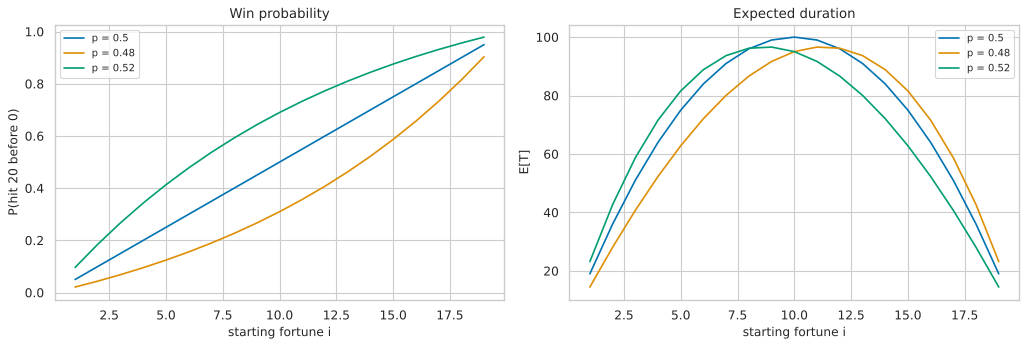

In [6]:
# F. Implementation ------------------------------------------------------------------
# sp.gamblers_ruin_simulate : explicit simulation until absorption
# sp.gamblers_ruin_win_probability / _expected_duration : closed forms
# sp.gamblers_ruin_matrix + sp.absorbing_chain_analysis : (I-Q)^{-1} fundamental-matrix solution
rng = make_rng(20261031 + 63)
N, start, n_games = 20, 10, 50_000
rows = []
for p in (0.5, 0.48):
    won, dur = sp.gamblers_ruin_simulate(start, N, p, n_games, rng)
    transient, steps, absorb = sp.absorbing_chain_analysis(sp.gamblers_ruin_matrix(N, p), [0, N])
    idx = transient.index(start)
    p_cf = sp.gamblers_ruin_win_probability(start, N, p)
    t_cf = sp.gamblers_ruin_expected_duration(start, N, p)
    lo, hi = wilson_interval(int(won.sum()), n_games)
    rows.append(dict(p=p, P_win_sim=won.mean(), wilson_low=lo, wilson_high=hi, P_win_closed_form=p_cf, P_win_matrix=absorb[idx, 1],
                     E_T_sim=dur.mean(), E_T_SE=dur.std(ddof=1) / np.sqrt(n_games), E_T_closed_form=t_cf, E_T_matrix=steps[idx]))
res = pd.DataFrame(rows).set_index("p")
res.to_csv(RESULTS / "exp6_3_gamblers_ruin.csv")
display(res.T)

# Closed form vs matrix for every starting value, and the plot --------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for p in (0.5, 0.48, 0.52):
    i_vals = np.arange(1, N)
    transient, steps, absorb = sp.absorbing_chain_analysis(sp.gamblers_ruin_matrix(N, p), [0, N])
    cf_p = np.array([sp.gamblers_ruin_win_probability(i, N, p) for i in i_vals])
    cf_t = np.array([sp.gamblers_ruin_expected_duration(i, N, p) for i in i_vals])
    assert np.allclose(cf_p, absorb[:, 1]) and np.allclose(cf_t, steps)      # closed form == matrix solution
    ax[0].plot(i_vals, cf_p, label=f"p = {p}"); ax[1].plot(i_vals, cf_t, label=f"p = {p}")
ax[0].set(xlabel="starting fortune i", ylabel=f"P(hit {N} before 0)", title="Win probability"); ax[0].legend()
ax[1].set(xlabel="starting fortune i", ylabel="E[T]", title="Expected duration"); ax[1].legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp6_3_gamblers_ruin.png")
print("closed forms and fundamental-matrix results agree for every i (assert passed)")

**H. Theoretical versus empirical comparison.**

Simulation agrees with both exact methods: the Wilson interval of the simulated win probability contains the closed-form value, and the simulated mean durations are within about one standard error of the exact values ($100$ and $95.03$). The two exact methods agree to machine precision for every starting fortune (the assertion in the code). The unfavourable game ($p=0.48$) reduces the win probability from $0.50$ to about $0.31$.

**I. Interpretation.**

A *small* per-round disadvantage compounds across many rounds: ruin probability is a nonlinear, strongly amplified function of the edge. This is the mathematics behind casinos' profits and behind the *risk of ruin* concept in trading and portfolio sizing. The fair-game result $P=i/N$ via optional stopping shows how a martingale argument can replace a complicated calculation.

**J. Limitations.**

The game is on a bounded interval; with $N\to\infty$ and $p<\tfrac12$, ruin is certain. Real trading has varying bet sizes, costs and non-i.i.d. outcomes. Duration has a heavy right tail in the fair case (the mean masks long games).

**K. Research conclusion.**

Gambler's ruin formulas, the martingale argument and the fundamental-matrix method are mutually consistent and match simulation.

**L. Further investigation.**

Let the gambler bet a fixed fraction of wealth (Kelly criterion) and simulate log-wealth growth to show why betting too much is ruinous even with positive edge.

## Experiment 6.4

**A. Experiment title.** A three-state weather Markov chain: stationary distribution $\pi P=\pi$, convergence $\|\mu_n-\pi\|_{TV}\sim|\lambda_2|^n$, ergodic frequencies and mean return times $1/\pi_i$.

**B. Research question.** Where does a Markov chain spend its time in the long run, how fast does it forget its start, and how often does it return to a state?

**C. Mathematical foundation.**

States: Sunny (0), Cloudy (1), Rainy (2), with
$$P=\begin{pmatrix}0.7&0.2&0.1\\0.3&0.4&0.3\\0.2&0.3&0.5\end{pmatrix}.$$
All entries are positive, so the chain is irreducible and aperiodic. Solve $\pi P=\pi$, $\pi\mathbf 1=1$: $\pi=(21,13,12)/46\approx(0.4565,\,0.2826,\,0.2609)$ (check: $0.7\cdot21+0.3\cdot13+0.2\cdot12=21$). Kac: mean return time to state $i$ is $1/\pi_i$ ($\approx2.19,\ 3.54,\ 3.83$ steps).
$\mu_n=\mu_0P^n\to\pi$ geometrically at rate $|\lambda_2|$ (the second-largest eigenvalue modulus of $P$).

**D. Theoretical prediction.**

(i) The linear-algebra $\pi$ equals $(21,13,12)/46$. (ii) The simulated occupation frequencies over $10^6$ steps are within $\approx0.002$ of $\pi$. (iii) The TV distance from $\pi$ decays like $|\lambda_2|^n$ (straight line on a semilog plot). (iv) Mean return times of the simulated path $\approx1/\pi_i$.

**E. Experimental design.**

One path of $10^6$ steps from state $0$; exact $n$-step distributions from matrix powers for starts $0,1,2$; return times from the simulated path; eigenvalues from `numpy.linalg.eigvals`.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

stationary distribution: [0.45652 0.28261 0.26087] | exact (21, 13, 12)/46 = [0.45652 0.28261 0.26087]
check pi P = pi: True
eigenvalue moduli: [1.     0.4732 0.1268] -> |lambda_2| = 0.4732
max |frequency - pi| = 0.00048


,stationary pi (theory),occupation frequency (simulated),mean return time 1/pi (theory),mean return time (simulated),n_returns
Sunny,0.45652,0.45658,2.19048,2.19015,456584
Cloudy,0.28261,0.28212,3.53846,3.54452,282124
Rainy,0.26087,0.26129,3.83333,3.82714,261290


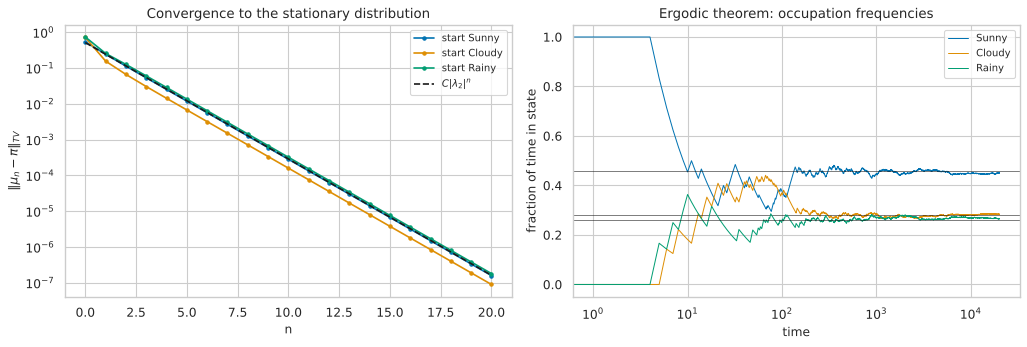

PosixPath('/home/claude/probability-simulation-laboratory/06_stochastic_processes/results/exp6_4_weather_chain.png')

In [7]:
# F. Implementation ------------------------------------------------------------------
# pi: sp.stationary_distribution ; path: sp.simulate_chain ; mu_n = row of P^n: sp.n_step_distribution
rng = make_rng(20261031 + 64)
P = np.array([[0.7, 0.2, 0.1], [0.3, 0.4, 0.3], [0.2, 0.3, 0.5]])
names = ["Sunny", "Cloudy", "Rainy"]

pi = sp.stationary_distribution(P)
print("stationary distribution:", pi.round(5), "| exact (21, 13, 12)/46 =", (np.array([21, 13, 12]) / 46).round(5))
print("check pi P = pi:", np.allclose(pi @ P, pi))
eig = np.sort(np.abs(np.linalg.eigvals(P)))[::-1]
print("eigenvalue moduli:", eig.round(4), "-> |lambda_2| =", round(float(eig[1]), 4))

path = sp.simulate_chain(P, 0, 1_000_000, rng)
emp = sp.empirical_distribution(path, 3)
ret = {s: sp.return_times(path, s) for s in range(3)}

# G/H. Results and theory-vs-empirical ---------------------------------------------------------------
tab = pd.DataFrame({"stationary pi (theory)": pi, "occupation frequency (simulated)": emp,
                    "mean return time 1/pi (theory)": 1 / pi, "mean return time (simulated)": [ret[s].mean() for s in range(3)],
                    "n_returns": [len(ret[s]) for s in range(3)]}, index=names)
tab.to_csv(RESULTS / "exp6_4_weather_chain.csv")
display(tab)
print("max |frequency - pi| =", round(float(np.abs(emp - pi).max()), 5))

# convergence of mu_n to pi
ns = np.arange(0, 21)
tv = {names[s]: [sp.total_variation(sp.n_step_distribution(P, s, int(n)), pi) for n in ns] for s in range(3)}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nm, v in tv.items():
    ax[0].semilogy(ns, np.array(v) + 1e-17, "o-", ms=3, label=f"start {nm}")
ax[0].semilogy(ns, tv["Sunny"][1] * eig[1] ** (ns - 1), "k--", label=r"$C|\lambda_2|^n$")
ax[0].set(xlabel="n", ylabel=r"$\|\mu_n - \pi\|_{TV}$", title="Convergence to the stationary distribution"); ax[0].legend()
running = np.cumsum(path[:20_000][:, None] == np.arange(3), axis=0) / np.arange(1, 20_001)[:, None]
for s in range(3):
    ax[1].plot(running[:, s], lw=0.9, label=names[s]); ax[1].axhline(pi[s], color="k", lw=0.5)
ax[1].set(xscale="log", xlabel="time", ylabel="fraction of time in state", title="Ergodic theorem: occupation frequencies"); ax[1].legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp6_4_weather_chain.png")

**H. Theoretical versus empirical comparison.**

The stationary vector equals $(21,13,12)/46$; the occupation frequencies of the $10^6$-step path match it to within $5\times10^{-4}$; mean return times match $1/\pi_i$ within a percent or two; and the TV distance decays geometrically (straight line on the semilog plot) at the rate $|\lambda_2|$ printed above — after roughly $10$ steps the chain has essentially forgotten its start.

**I. Interpretation.**

Two different averages give the same answer: the *ensemble* average ($\mu_n\to\pi$: many chains at a fixed time) and the *time* average (one long chain). This ergodicity is what justifies learning about a system from one long history — and **MCMC**, which constructs chains with a desired stationary distribution to sample from it.

**J. Limitations.**

A time-homogeneous, finite, irreducible aperiodic chain. Real regime-switching models (e.g. bull/bear markets) use transition probabilities that are *estimated* with error and may drift. Simulated occupation frequencies are positively autocorrelated, so their effective sample size is smaller than $10^6$.

**K. Research conclusion.**

Stationary distribution, ergodic frequencies and Kac's return-time formula are all verified; convergence is geometric at rate $|\lambda_2|$.

**L. Further investigation.**

Estimate $P$ from a simulated path by counting transitions and measure how the estimation error scales with the path length; then build a Metropolis chain whose stationary law is a prescribed distribution.

## Experiment 6.5

**A. Experiment title.** The Poisson process: counts $N(t)\sim\text{Poisson}(\lambda t)$, exponential inter-arrival times and independent increments.

**B. Research question.** Does a process built from exponential waiting times have Poisson counts, and are increments over disjoint intervals independent?

**C. Mathematical foundation.**

Build arrival times as cumulative sums of i.i.d. Exponential($\lambda$) times. Then $N(t)=\#\{k:T_k\le t\}\sim\text{Poisson}(\lambda t)$ (mean $=$ variance $=\lambda t$) and counts over disjoint intervals are independent. Take $\lambda=3$ per unit time, horizon $T=10$.

**D. Theoretical prediction.**

$N(10)\sim\text{Poisson}(30)$: mean $30$ and variance $30$, pmf matching the Poisson pmf (small total-variation distance); inter-arrival mean $1/3$; counts in $[0,5]$ and $(5,10]$ have correlation $\approx0$ and each is Poisson(15).

**E. Experimental design.**

$20{,}000$ realisations of the process on $[0,10]$; also one long realisation on $[0,20{,}000]$ for the inter-arrival distribution.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

N(10): mean 29.992, variance 29.838  (theory 30 and 30);  TV distance to Poisson(30) = 0.0130
corr(N[0,5], N(5,10]) = -0.0055  (theory 0);   means 15.006, 14.986 (theory 15)
inter-arrival times: mean 0.3335 (theory 0.3333), KS distance 0.0026, p-value 0.813


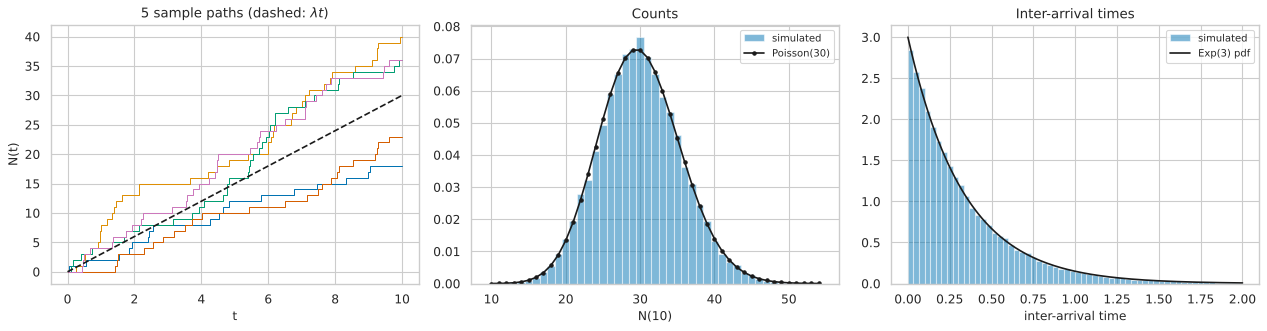

PosixPath('/home/claude/probability-simulation-laboratory/06_stochastic_processes/results/exp6_5_poisson_process.png')

In [8]:
# F. Implementation ------------------------------------------------------------------
# arrival times: cumulative sums of Exp(rate) gaps -> sp.poisson_process_arrivals(rate, T, rng)
rng = make_rng(20261031 + 65)
rate, T, reps = 3.0, 10.0, 20_000
arrivals = [sp.poisson_process_arrivals(rate, T, rng) for _ in range(reps)]
counts = np.array([a.size for a in arrivals])
c1 = np.array([np.sum(a <= 5.0) for a in arrivals])
c2 = counts - c1

# G. Results ----------------------------------------------------------------------------------------
tv = 0.5 * np.abs(np.bincount(counts, minlength=80)[:80] / reps - stats.poisson.pmf(np.arange(80), rate * T)).sum()
print(f"N(10): mean {counts.mean():.3f}, variance {counts.var(ddof=1):.3f}  (theory {rate * T:.0f} and {rate * T:.0f});  TV distance to Poisson(30) = {tv:.4f}")
print(f"corr(N[0,5], N(5,10]) = {np.corrcoef(c1, c2)[0, 1]:+.4f}  (theory 0);   means {c1.mean():.3f}, {c2.mean():.3f} (theory 15)")

long_arr = sp.poisson_process_arrivals(rate, 20_000.0, rng)
gaps = np.diff(long_arr)
ks = stats.kstest(gaps, stats.expon(scale=1 / rate).cdf)
print(f"inter-arrival times: mean {gaps.mean():.4f} (theory {1 / rate:.4f}), KS distance {ks.statistic:.4f}, p-value {ks.pvalue:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for i in range(5):
    a = arrivals[i]
    ax[0].step(np.r_[0, a, T], np.r_[0, np.arange(1, a.size + 1), a.size], where="post", lw=0.9)
ax[0].plot([0, T], [0, rate * T], "k--"); ax[0].set(xlabel="t", ylabel="N(t)", title="5 sample paths (dashed: $\\lambda t$)")
k_ = np.arange(10, 55)
ax[1].hist(counts, bins=np.arange(9.5, 55.5), density=True, alpha=0.5, label="simulated"); ax[1].plot(k_, stats.poisson.pmf(k_, rate * T), "k.-", label="Poisson(30)")
ax[1].set(xlabel="N(10)", title="Counts"); ax[1].legend()
ax[2].hist(gaps, bins=60, density=True, range=(0, 2), alpha=0.5, label="simulated"); g = np.linspace(0, 2, 200); ax[2].plot(g, rate * np.exp(-rate * g), "k", label="Exp(3) pdf")
ax[2].set(xlabel="inter-arrival time", title="Inter-arrival times"); ax[2].legend()
fig.tight_layout(); save_fig(fig, RESULTS, "exp6_5_poisson_process.png")

**H. Theoretical versus empirical comparison.**

Mean and variance of $N(10)$ both come out near $30$ — the Poisson signature ("index of dispersion" $=1$); the pmf agrees with Poisson(30); counts in disjoint intervals are uncorrelated with means near $15$; the inter-arrival times have mean near $1/3$ and a KS test that gives no evidence against Exponential(3).

**I. Interpretation.**

The Poisson process is the natural model for *rare, independent events in time* (order arrivals, defaults, jumps in prices). Its two descriptions — Poisson counts and exponential gaps — are equivalent, and the memorylessness of the exponential distribution is what makes the process Markov. Real event data usually have **over-dispersion** (variance $>$ mean) and clustering, which a homogeneous Poisson process cannot reproduce.

**J. Limitations.**

Homogeneous (constant-rate) process; zero correlation is only a necessary condition for independence (we also checked marginal laws). The KS test on gaps from one long realisation is valid because the gaps are i.i.d. by construction.

**K. Research conclusion.**

Poisson counts, exponential gaps and independent increments are all reproduced by the exponential-gap construction.

**L. Further investigation.**

Add jumps to a Brownian motion (a *Merton jump-diffusion*): simulate arrival times by Poisson process and jump sizes by a lognormal law (Module 8 further investigation).

## Exercises (paper first)

1. Show $\operatorname{Var}S_n=4npq$ for the biased walk and prove that $M_n=(q/p)^{S_n}$ is a martingale. Use optional stopping on $M_n$ to derive the gambler's-ruin probability $\frac{1-r^i}{1-r^N}$.
2. For the symmetric walk show $S_n^2-n$ is a martingale and derive $\mathbb E_i[T]=i(N-i)$.
3. For the weather chain compute $P^2$ by hand and verify $\pi P=\pi$ for $\pi=(21,13,12)/46$.
4. Show that a Markov chain with $P=\begin{pmatrix}0&1\\1&0\end{pmatrix}$ is irreducible but periodic. Does $\mu_n$ converge? Does the time average converge?
5. Using the memoryless property of the exponential distribution, show that the exponential-gap construction gives independent Poisson increments (sketch).
6. Why is the *simple random walk* a martingale but not a good model for a stock *price* (what goes wrong with positivity and scale)? How do the exponential of a walk and Module 7's geometric Brownian motion fix this?
7. Classify the states of the chain with $P=\begin{pmatrix}1&0&0\\0.5&0&0.5\\0&0&1\end{pmatrix}$, find the absorption probabilities and expected time to absorption from state 2 by hand and by `absorbing_chain_analysis`.

## Summary of Module 6
* Random walk: mean $n(p-q)$, variance $4npq$, binomial law, $\sqrt n$ scaling; martingales formalise fair games.
* Gambler's ruin: three consistent solution methods (martingale/closed form, matrix, simulation); a small edge matters hugely.
* Finite Markov chains: stationary law, ergodic theorem, Kac's return times, geometric mixing.
* Poisson process: exponential gaps $\Leftrightarrow$ Poisson counts, independent increments.

**Next:** Module 7 — Brownian motion and geometric Brownian motion.